# Identifying, Selecting, and Using a Machine Learning Model
### A live walkthrough: Hugging Face, the sites around it, and Python

**The scenario.** A bank's support team gets thousands of customer messages a day. Each one has to reach the right queue: card problems, transfers, top-ups, and so on. We will pick, evaluate, and ship a model that routes them.

**The thesis.** Choosing a model is an engineering decision made under constraints. Leaderboards and model cards only shortlist. Our own evaluation makes the choice, and shipping starts the work rather than ending it.

| Phase | What we do | Where |
|---|---|---|
| **1 · Identify** | Frame the decision, map it to an ML task, write constraints as tests | Dataset page, this notebook |
| **2 · Select** | Search the Hub, review model cards, run one shared evaluation, decide with a matrix | huggingface.co, MTEB leaderboard, scikit-learn map |
| **3 · Use** | Publish with a model card, load safely, serve, break it, monitor drift, fall back | This notebook, optional Gradio UI |

How to read this notebook:
- **🌐 SITE STOP** cells tell you which page to open, what to click, and what point to make there.
- **💡 KEY IDEAS** cells hold the lecture material.
- **🙋 ASK THE ROOM** cells are discussion prompts.

## Instructor run-of-show (about 80 minutes)

| Min | Section | Mode |
|---|---|---|
| 0–5 | 0 · Setup and framing | Talk |
| 5–15 | 1 · Identify: dataset page, data, constraints | Site + code |
| 15–25 | 2.1 · Search the Hub | Site + code |
| 25–33 | 2.2 · Review model cards and files | Site + code |
| 33–38 | 2.3 · Leaderboards (MTEB) | Site |
| 38–55 | 2.4–2.6 · Evaluate four candidates | Code (cached results) |
| 55–62 | 2.7 · Decision matrix | Code + discussion |
| 62–75 | 3 · Package, load safely, serve, break, monitor | Code + optional UI |
| 75–80 | 4 · Debrief and team activity | Discussion |

### Before class (do this the day before)
1. **PyTorch for the GTX 1080 Ti.** These are Pascal cards (sm_61). PyTorch **2.14 is the last release with prebuilt wheels for them**, and only in the CUDA 12.6 build. Newer CUDA 12.8+/13.x wheels will fail with "no kernel image is available".
   `pip install torch==2.14.0 --index-url https://download.pytorch.org/whl/cu126`
   Your NVIDIA driver must support CUDA 12.6 or newer. `nvidia-smi` shows the highest supported version in its header.
2. `pip install -r requirements.txt` (the other packages).
3. Run the whole notebook once, top to bottom. Slow steps (zero-shot evaluation and fine-tuning) cache their results under `artifacts/`. In class they load in seconds unless you set the matching `RERUN_*` flag.
4. Optional: set `HF_HOME` to a cache directory that the run filled. If the network fails in class, set `HF_HUB_OFFLINE=1` and everything still loads.
5. Keep a fully executed copy (`File → Save As… walkthrough-executed.ipynb`) open in a second tab as a backup.

---
## 0 · Setup

In [1]:
import os
# Both GTX 1080 Ti cards stay visible. The Trainer uses both for fine-tuning; inference runs on cuda:0.
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# os.environ["HF_HOME"] = "/data/hf-cache"     # uncomment: the cache filled during your pre-class run
# os.environ["HF_HUB_OFFLINE"] = "1"           # uncomment if the network fails in class

import json, time, pickle, random, warnings, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers, datasets, huggingface_hub, sklearn, sentence_transformers

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 80)

SEED = 42
transformers.set_seed(SEED)
random.seed(SEED); np.random.seed(SEED)

ART = Path("artifacts"); ART.mkdir(exist_ok=True)
RESULTS = ART / "results"; RESULTS.mkdir(exist_ok=True)

# Rehearsal mode: small subsets so the whole notebook runs in a few minutes.
QUICK = os.environ.get("DEMO_QUICK", "0") == "1"

# Set True to recompute a cached slow step in class.
RERUN_ZERO_SHOT = False
RERUN_FINETUNE = False

for lib in (torch, transformers, datasets, huggingface_hub, sklearn, sentence_transformers):
    print(f"{lib.__name__:24s}{lib.__version__}")
print("QUICK mode" if QUICK else "Full mode")

torch                   2.14.1+cu126
transformers            5.19.0
datasets                5.1.0
huggingface_hub         1.33.0
sklearn                 1.9.1
sentence_transformers   6.1.0
Full mode


In [2]:
def check_gpus():
    # Report the GPUs, prove CUDA kernels actually run, and choose a training precision.
    if not torch.cuda.is_available():
        print("No CUDA GPU visible: everything runs on CPU (fine-tuning will be slow).")
        return "cpu", "fp32"
    for i in range(torch.cuda.device_count()):
        major, minor = torch.cuda.get_device_capability(i)
        mem = torch.cuda.get_device_properties(i).total_memory / 2**30
        print(f"cuda:{i}  {torch.cuda.get_device_name(i)}  sm_{major}{minor}  {mem:.1f} GB")
    print("Architectures in this PyTorch build:", " ".join(torch.cuda.get_arch_list()))
    try:
        (torch.ones(8, device="cuda:0") * 2).sum().item()
    except RuntimeError as e:
        print("\nCUDA kernels FAILED to run:", str(e).splitlines()[0])
        print("Fix for Pascal cards (GTX 10xx):")
        print("  pip install torch==2.14.0 --index-url https://download.pytorch.org/whl/cu126")
        return "cpu", "fp32"
    major, minor = torch.cuda.get_device_capability(0)
    # bf16 needs Ampere (sm_80+); fp16 pays off with tensor cores (sm_70+); Pascal stays fp32.
    precision = "bf16" if major >= 8 else "fp16" if major >= 7 else "fp32"
    print(f"\nKernels run. Training precision: {precision}")
    return "cuda:0", precision

DEVICE, PRECISION = check_gpus()

cuda:0  NVIDIA GeForce GTX 1080 Ti  sm_61  10.9 GB
cuda:1  NVIDIA GeForce GTX 1080 Ti  sm_61  10.9 GB
Architectures in this PyTorch build: sm_50 sm_60 sm_70 sm_75 sm_80 sm_86 sm_90

Kernels run. Training precision: fp32


---
## 1 · Identify: frame the decision before naming a model

### 💡 KEY IDEAS: Start from the decision, not the model
| Question | For our scenario |
|---|---|
| **What action changes?** | Which queue a message goes to |
| **What does an error cost?** | A misroute means a re-queue, a slower reply, and an annoyed customer. A missed rare intent (say, a stolen card) costs more than a common one. |
| **What happens today?** | People triage by hand. That is our baseline *and* our fallback. |

### Translate the question into an ML task
| The question | ML task | Output |
|---|---|---|
| Will this customer leave? | Binary classification | Probability |
| **Which queue should this message go to?** | **Multiclass classification** | **Label + confidence** |
| How many units next week? | Regression / forecasting | Value + interval |
| Which documents answer this? | Retrieval / ranking | Ordered list |
| Is this transaction unusual? | Anomaly detection | Score |
| Draft or summarize this text | Generation | Text |

### Do we need ML at all?
ML fits when the pattern is too complex to hand-code, labeled examples exist, errors are recoverable, and the pattern shifts over time. Think twice when a rule or a SQL query is good enough, there is no reliable label, or a single unreviewed error is catastrophic. **Build the simple baseline first. It is the bar every model has to beat.**

### 🌐 SITE STOP 1: The dataset pages
1. Open **https://huggingface.co/datasets/PolyAI/banking77**, the original release.
   - The **dataset viewer is broken**: "Dataset scripts are no longer supported." Recent `datasets` releases dropped loading scripts.
   - *Point:* data and models rot. Pin versions and keep a copy of what you trained on.
2. Open **https://huggingface.co/datasets/mteb/banking77**, a parquet mirror maintained for the MTEB benchmark.
   - The **viewer works**. Scroll the rows, open the `label_text` column's distribution, and try the **SQL console** (`SELECT label_text, count(*) FROM train GROUP BY 1 ORDER BY 2`).
   - Compare **licenses**: the original card says **CC-BY-4.0**, the mirror says **MIT**. A mirror can't relicense someone else's data. *Point:* license provenance comes from the original source, not from whoever re-uploaded it.
3. Note the data: 10,003 train and 3,080 test messages, 77 intents, English only, from one bank's domain.

🙋 **ASK THE ROOM:** This mirror exists *because* banking77 is an MTEB benchmark task. Why might that matter when we read the MTEB leaderboard later?

In [3]:
GITHUB_CSV = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/"

def load_banking77():
    # Prefer the Hub parquet mirror; fall back to the original authors' CSVs on GitHub.
    try:
        ds = datasets.load_dataset("mteb/banking77")
        tr = ds["train"].to_pandas().rename(columns={"label_text": "intent"})[["text", "intent"]]
        te = ds["test"].to_pandas().rename(columns={"label_text": "intent"})[["text", "intent"]]
        return tr, te, "huggingface.co/datasets/mteb/banking77"
    except Exception as e:
        print(f"Hub load failed ({type(e).__name__}); using the original CSVs from GitHub.")
        tr = pd.read_csv(GITHUB_CSV + "train.csv").rename(columns={"category": "intent"})
        te = pd.read_csv(GITHUB_CSV + "test.csv").rename(columns={"category": "intent"})
        return tr, te, "github.com/PolyAI-LDN/task-specific-datasets"

full_train, test_df, DATA_SOURCE = load_banking77()
LABELS = sorted(full_train["intent"].unique())
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
print(f"Source: {DATA_SOURCE}")
print(f"train={len(full_train):,}  test={len(test_df):,}  intents={len(LABELS)}")
full_train.sample(8, random_state=SEED)

Source: huggingface.co/datasets/mteb/banking77
train=9,993  test=3,076  intents=77


,text,intent
3123,What are the limits to where my card will be accepted?,card_acceptance
1441,I would like to change currency,exchange_via_app
6282,I have lost my credit card in the ATM!,card_swallowed
39,My card still hasn't been delivered,card_arrival
4094,Can you deliver the PIN separately?,get_physical_card
1599,I am 16 and just started working at McDonalds can I deposit my checks at you...,age_limit
4381,Whats the maximum number of disposable cards that I can get?,disposable_card_limits
7510,Been trying to transfer money this morning but keep getting rejected. I don'...,failed_transfer


In [4]:
from sklearn.model_selection import train_test_split

# Hold out a validation split from train (for tuning and thresholds). The test split stays FROZEN.
train_df, val_df = train_test_split(full_train, test_size=0.1, stratify=full_train["intent"], random_state=SEED)

if QUICK:   # rehearsal only
    train_df = train_df.groupby("intent", group_keys=False).head(20)
    val_df = val_df.groupby("intent", group_keys=False).head(4)
    test_df = test_df.groupby("intent", group_keys=False).head(5)

train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

# Fingerprint the test set so we can prove later that nobody tuned against a different one.
import hashlib
TEST_FINGERPRINT = hashlib.sha256("\n".join(test_df["text"]).encode()).hexdigest()[:12]
print(f"train={len(train_df):,} val={len(val_df):,} test={len(test_df):,}  test fingerprint={TEST_FINGERPRINT}")

train=8,993 val=1,000 test=3,076  test fingerprint=e62ee22558ec


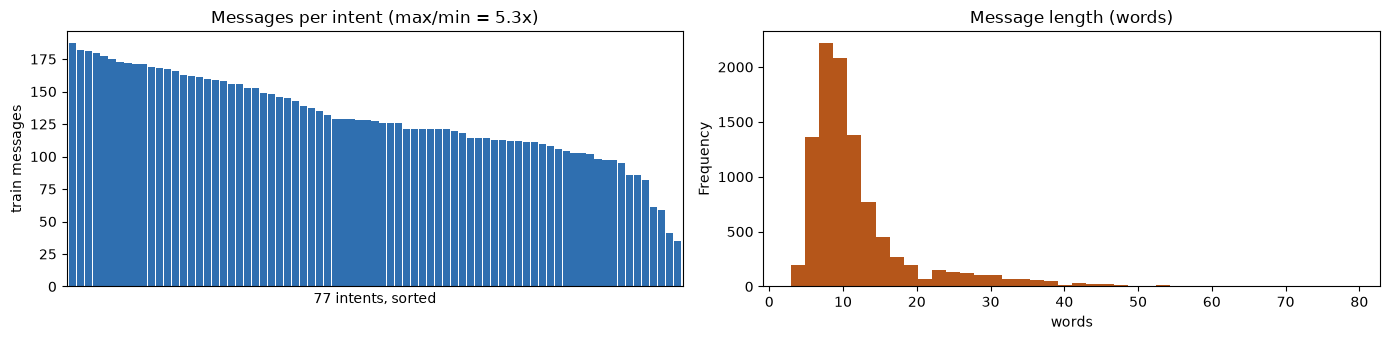

Smallest intents: lost_or_stolen_card, card_swallowed, card_acceptance, virtual_card_not_working, contactless_not_working


In [5]:
counts = full_train["intent"].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
counts.plot.bar(ax=ax[0], width=0.9, color="#2F6FB0")
ax[0].set_xticks([]); ax[0].set_title(f"Messages per intent (max/min = {counts.max()/counts.min():.1f}x)")
ax[0].set_xlabel("77 intents, sorted"); ax[0].set_ylabel("train messages")
full_train["text"].str.split().str.len().plot.hist(bins=40, ax=ax[1], color="#B5561A")
ax[1].set_title("Message length (words)"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.show()
print("Smallest intents:", ", ".join(counts.tail(5).index))

### 💡 KEY IDEAS: Write constraints down as tests
Constraints prune the candidate list faster than accuracy does. Write each one as a number or a yes/no, **before** anyone sees results, so nobody can bend a constraint to fit their favorite model.

| Constraint | Why it matters |
|---|---|
| **Latency**: p95 budget per request | Routing happens while the customer waits |
| **Cost**: per prediction at expected volume | CPU serving is far cheaper than a GPU fleet |
| **Data and privacy**: can text leave our boundary? | Messages contain account details |
| **Explainability**: who needs a reason? | Agents may ask why a ticket landed with them |
| **Licensing**: model and data licenses | Commercial use, attribution |
| **Hardware and ops**: where it runs, who is on call | Our serving tier is CPU-only |

🙋 **ASK THE ROOM:** Set the latency budget now, out loud. Edit the cell below.

In [ ]:
CONSTRAINTS = {
    "p95_latency_ms_cpu": 100,                 # MS set with the class BEFORE seeing results
    "allowed_licenses": {"apache-2.0", "mit", "bsd-3-clause", "cc-by-4.0"},
    "data_may_leave_environment": False,       # rules out hosted APIs before we test anything
}
CONSTRAINTS

{'p95_latency_ms_cpu': 100,
 'allowed_licenses': {'apache-2.0', 'bsd-3-clause', 'cc-by-4.0', 'mit'},
 'data_may_leave_environment': False}

---
## 2 · Select: candidates, evidence, evaluation, decision

### 💡 KEY IDEAS: Four paths to a candidate
| Path | Example | Data you need | Control | Ops burden |
|---|---|---|---|---|
| Train it yourself | TF-IDF + logistic regression; boosted trees | Labeled domain data | Full | Training and serving |
| Adapt a pretrained model | Fine-tune a small encoder; LoRA on an open LLM Low Rank Adaptation| Hundreds to thousands of examples | High | GPUs for tuning |
| Self-host as-is | Open-weight model on your GPUs | An eval set | High | Serving, patching |
| Call a hosted API | Hosted LLM with prompting or RAG | An eval set | Limited | Low infra, vendor risk |

Every path needs an **evaluation set**. Only the first two need a training set.

### Match the model family to the data
| Your data | Strong first choice |
|---|---|
| Tabular, mixed types | Gradient-boosted trees |
| Small n, must explain | Regularized linear model or GAM |
| **Short text, plenty of labels** | **Linear model on TF-IDF; pretrained encoder** |
| Images, audio, long text | Pretrained neural model |
| Very few labels | Zero- or few-shot foundation model |

### 🌐 SITE STOP 2: scikit-learn's estimator map
Open **https://scikit-learn.org/stable/machine_learning_map.html**. Trace our path: *>50 samples → predicting a category → labeled data → text data*. The map's own caption calls it "a bit of a rough guide". *Point:* heuristics build the shortlist, and evaluation makes the choice.

### 🌐 SITE STOP 3: Searching the Hub
**The method: search by the approach, sort by adoption, then apply the requirements.** Open **https://huggingface.co/models** and narrow it down live:
1. **Tasks → Text Classification**, sorted by **Most downloads**. These are models *already fine-tuned for someone else's labels* (sentiment, toxicity…). Switch the sort to **Trending**: how much does the list change?
2. Search **"banking77"**. Many community models are *already trained on our exact dataset*.
3. Now one search per rung of the adaptation ladder:
   - **Zero-shot:** [Tasks → Zero-Shot Classification, sorted by downloads](https://huggingface.co/models?pipeline_tag=zero-shot-classification&sort=downloads). `facebook/bart-large-mnli` is #1.
   - **Embeddings:** [Tasks → Sentence Similarity, Libraries → sentence-transformers](https://huggingface.co/models?pipeline_tag=sentence-similarity&library=sentence-transformers&sort=downloads). `sentence-transformers/all-MiniLM-L6-v2` is #1 by a wide margin.
   - **A base model to fine-tune:** [Tasks → **Fill-Mask**, Libraries → Transformers, Languages → English](https://huggingface.co/models?pipeline_tag=fill-mask&library=transformers&language=en&sort=downloads). `distilbert/distilbert-base-uncased` is near the top and the smallest of the leaders.

*Point:* a base model is tagged with its **pretraining** task (fill-mask: predict a hidden word), not with Text Classification. That's why step 1 never finds it.

Now run the same searches in code, which is reproducible and scriptable:

In [3]:
import pandas as pd
from huggingface_hub import HfApi
api = HfApi()

def hub_search(limit=8, **query):
    rows = []
    for m in api.list_models(limit=limit, sort="downloads",
                             expand=["downloads", "likes", "pipeline_tag", "library_name", "cardData", "safetensors", "lastModified"],
                             **query):
        rows.append({
            "model": m.id,
            "downloads/mo": m.downloads,
            "likes": m.likes,
            "task": m.pipeline_tag,
            "license": getattr(m.card_data, "license", None) if m.card_data else None,
            "params (M)": round(m.safetensors.total / 1e6, 1) if m.safetensors else None,
            "updated": str(m.last_modified)[:10] if m.last_modified else None,
        })
    return pd.DataFrame(rows)

print("Most-downloaded text classifiers")
display(hub_search(pipeline_tag="text-classification"))

Most-downloaded text classifiers


,model,downloads/mo,likes,task,license,params (M),updated
0,BAAI/bge-reranker-v2-m3,16000331,1243,text-classification,apache-2.0,567.8,2024-06-24
1,ProsusAI/finbert,4346199,1272,text-classification,cc-by-nc-sa-4.0,109.5,2026-10-12
2,SamLowe/roberta-base-go_emotions,3880580,700,text-classification,mit,124.7,2026-05-13
3,BAAI/bge-reranker-base,3864287,254,text-classification,mit,278.0,2024-06-24
4,meta-llama/Prompt-Guard-86M,2737390,422,text-classification,llama3.1,278.8,2025-11-12
5,distilbert/distilbert-base-uncased-finetuned-s...,2703470,970,text-classification,apache-2.0,67.0,2023-12-19
6,cardiffnlp/twitter-roberta-base-sentiment-latest,2553472,842,text-classification,cc-by-4.0,NaN,2025-08-04
7,yiyanghkust/finbert-tone,1252710,228,text-classification,NaN,NaN,2022-10-17


In [ ]:
print("Models whose names or tags mention banking77")
community = hub_search(search="banking77", limit=10)
display(community)

Models whose names or tags mention banking77


,model,downloads/mo,likes,task,license,params (M),updated
0,EQTYLab/Llama-3.1-Nemotron-Nano-4B-v1.1-banking77,985,2,text-generation,other,4512.7,2026-10-01
1,saivamshiatukuri/bge-m3-banking77-lora,693,1,NaN,mit,NaN,2026-09-22
2,philschmid/distilbert-onnx-banking77,609,6,text-classification,NaN,NaN,2022-10-01
3,optimum/distilbert-base-uncased-finetuned-banking77,168,4,text-classification,apache-2.0,67.0,2023-09-12
4,philschmid/BERT-Banking77,160,15,text-classification,NaN,NaN,2022-12-05
5,mradermacher/banking77-qwen3-06b-GGUF,150,1,NaN,NaN,NaN,2026-03-03
6,mrm8488/distilroberta-finetuned-banking77,111,9,text-classification,NaN,82.2,2023-04-04
7,lxyuan/FunctionGemma-270M-banking77-router,109,0,text-generation,gemma,268.1,2026-08-30
8,rithwik-db/bert-base-cased_banking77_10000,83,0,sentence-similarity,NaN,NaN,2023-04-10
9,philschmid/DistilBERT-Banking77,53,0,text-classification,NaN,NaN,2022-06-24


One search per rung of the ladder. Each candidate comes from the top of one of these lists, **after** the requirements are applied (see the shortlist below):

In [ ]:
print("Rung: zero-shot. Pick: facebook/bart-large-mnli")
display(hub_search(pipeline_tag="zero-shot-classification", limit=8))

print("Rung: frozen embeddings. Pick: sentence-transformers/all-MiniLM-L6-v2")
display(hub_search(pipeline_tag="sentence-similarity", filter="sentence-transformers", limit=8))

print("Rung: fine-tuning base (English, transformers). Pick: distilbert/distilbert-base-uncased")
display(hub_search(pipeline_tag="fill-mask", filter=["transformers", "en"], limit=10))

Rung: zero-shot. Pick: facebook/bart-large-mnli


,model,downloads/mo,likes,task,license,params (M),updated
0,facebook/bart-large-mnli,2564335,1623,zero-shot-classification,mit,407.3,2023-09-05
1,joeddav/xlm-roberta-large-xnli,2010957,293,zero-shot-classification,mit,560.9,2024-10-16
2,MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7,884409,394,zero-shot-classification,mit,278.8,2024-04-11
3,cross-encoder/nli-deberta-v3-base,495862,50,zero-shot-classification,apache-2.0,184.4,2025-04-11
4,MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli,452498,226,zero-shot-classification,mit,184.4,2024-04-11
5,cross-encoder/nli-deberta-v3-small,382747,16,zero-shot-classification,apache-2.0,141.9,2025-04-15
6,typeform/distilbert-base-uncased-mnli,331691,49,zero-shot-classification,NaN,67.0,2023-03-22
7,cross-encoder/nli-MiniLM2-L6-H768,263586,15,zero-shot-classification,apache-2.0,82.1,2025-04-15


Rung: frozen embeddings. Pick: sentence-transformers/all-MiniLM-L6-v2


,model,downloads/mo,likes,task,license,params (M),updated
0,sentence-transformers/all-MiniLM-L6-v2,223255538,6240,sentence-similarity,apache-2.0,22.7,2026-06-01
1,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,48432191,1428,sentence-similarity,apache-2.0,117.7,2026-01-28
2,BAAI/bge-m3,32850245,3843,sentence-similarity,mit,NaN,2024-07-03
3,sentence-transformers/all-mpnet-base-v2,18171463,1381,sentence-similarity,apache-2.0,109.5,2025-08-19
4,nomic-ai/nomic-embed-text-v1.5,12870656,950,sentence-similarity,apache-2.0,136.7,2026-04-07
5,intfloat/multilingual-e5-small,10406929,443,sentence-similarity,mit,117.7,2026-04-02
6,sentence-transformers/paraphrase-multilingual-mpnet-base-v2,9626205,531,sentence-similarity,apache-2.0,278.0,2025-08-19
7,intfloat/multilingual-e5-base,6817346,393,sentence-similarity,mit,278.0,2026-04-02


Rung: fine-tuning base (English, transformers). Pick: distilbert/distilbert-base-uncased


,model,downloads/mo,likes,task,license,params (M),updated
0,google-bert/bert-base-uncased,35402796,3399,fill-mask,apache-2.0,110.1,2024-02-19
1,FacebookAI/xlm-roberta-base,12321047,930,fill-mask,mit,278.9,2024-02-19
2,FacebookAI/roberta-base,8085334,669,fill-mask,mit,124.7,2024-02-19
3,distilbert/distilbert-base-uncased,7771141,1474,fill-mask,apache-2.0,67.0,2024-05-06
4,FacebookAI/roberta-large,6040093,323,fill-mask,mit,355.4,2024-02-19
5,microsoft/mdeberta-v3-base,5759808,247,fill-mask,mit,NaN,2023-04-06
6,answerdotai/ModernBERT-base,4029508,1121,fill-mask,apache-2.0,149.7,2025-01-15
7,google-bert/bert-base-cased,3496320,381,fill-mask,apache-2.0,108.9,2024-02-19
8,microsoft/deberta-v3-base,2788959,450,fill-mask,mit,NaN,2022-09-22
9,FacebookAI/xlm-roberta-large,2659267,540,fill-mask,mit,561.2,2024-02-19


🙋 **ASK THE ROOM:** In each list, why not just take #1?
- **Zero-shot:** #1 *is* our pick, but #2–#3 are multilingual, which we don't need. Smaller NLI models further down would likely be faster. We keep the popular one so we can watch it hit the latency wall; a sharp student can add a smaller one as candidate F.
- **Embeddings:** #1 is also the smallest English model in the top 10.
- **Fine-tuning base:** #1 is `bert-base-uncased` (~110M params). DistilBERT (~67M) is the smallest of the leaders: faster on CPU and on our 1080 Ti cards.

Download counts only put a model on the list. The requirements decide.

🙋 **ASK THE ROOM:** Several community models claim high accuracy on banking77. Can we just take the best one?

Not yet. We don't know their training data (did test messages leak in?), their evaluation split, or who published them. A reported score is only comparable to ours if we rerun it on **our** frozen test split.

### From search results to a shortlist: the business requirements
We don't pick models because they're popular. We cut the search results down with requirements that come from the business:

1. **Task fit:** English text classification, directly or as a base for it.
2. **Data stays in-house:** open weights we can run on our servers, not a hosted API.
3. **Commercial-use license:** MIT, Apache-2.0, BSD, or CC-BY.
4. **Fast on CPU:** p95 of 100 ms or less per message, which favors small models.
5. **Trainable on our hardware:** fine-tuning fits two GTX 1080 Ti cards in minutes.
6. **Trustworthy supply chain:** known publisher, a real model card, safetensors weights.
7. **A fair test:** not already trained on banking77.

Requirements 1–3 are hard filters. Requirements 4–5 are checked on paper now and **measured** below. Then we take one well-established model per rung of the adaptation ladder:

| # | Candidate | Rung | Hugging Face model | Size | License |
|---|---|---|---|---|---|
| **A** | TF-IDF + logistic regression | Simple baseline | none: built here with scikit-learn | ~4 MB | BSD-3-Clause |
| **B** | Zero-shot NLI | No training | [facebook/bart-large-mnli](https://huggingface.co/facebook/bart-large-mnli) | ~400M params | MIT |
| **C** | Frozen sentence embeddings + logistic regression | Cheap adaptation | [sentence-transformers/all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) | ~23M params | Apache-2.0 |
| **D** | Fine-tuned encoder | Full fine-tune | [distilbert/distilbert-base-uncased](https://huggingface.co/distilbert/distilbert-base-uncased) | ~67M params | Apache-2.0 |

**Left out on purpose:** community banking77 fine-tunes (fail requirement 7), hosted LLM APIs (fail requirement 2), and large models such as MTEB leaders or open LLMs (likely fail requirement 4 on CPU; a good extension exercise). B is kept even though it looks doubtful on requirement 4, so we can *watch* it fail.

🙋 **Predict the ranking now.** Write it on the board. We'll check it in 20 minutes.

In [ ]:
ZS_ID = "facebook/bart-large-mnli"
EMB_ID = "sentence-transformers/all-MiniLM-L6-v2"
FT_BASE = "distilbert-base-uncased"   # alternative: "answerdotai/ModernBERT-base" (slower on Pascal; no flash attention)
CANDIDATE_IDS = [ZS_ID, EMB_ID, FT_BASE]

### 💡 KEY IDEAS: Read the model card before the benchmark
Check six things:
1. **Intended use**, and the uses it rules out
2. **Training data**: sources, dates, languages, gaps
3. **Evaluation**: on which data, which slices, which metrics
4. **Limitations and bias**: what the authors say it gets wrong
5. **License and terms**: commercial use, attribution
6. **Format and footprint**: size, context length, **weight format**

A missing or thin card is itself a signal.

### 🌐 SITE STOP 4: A model page, tab by tab
Open **https://huggingface.co/facebook/bart-large-mnli**:
- **Model card**: grade it against the six checks out loud.
- **Right sidebar**: downloads last month, license tag, parameter count, **"Use this model"** (copy-ready code), and the **inference widget**. Try a banking message with a few candidate labels.
- **Files and versions**: `model.safetensors` *and* older pickle-based `pytorch_model.bin`. Click a `.bin` file to see the Hub's **pickle import scan** listing.
- **Community** tab: open issues and discussions, which signal maintenance.

Then open **https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2** and compare. Note the **256 word-piece truncation** and the training data list (Reddit, Stack Exchange, MS MARCO…): no banking data.

Now automate the review:

In [ ]:
from huggingface_hub import ModelCard

PICKLE_EXT = (".bin", ".pt", ".pth", ".pkl", ".pickle", ".ckpt")

def review_model(repo_id):
    info = api.model_info(repo_id, files_metadata=True, securityStatus=True)
    files = [(s.rfilename, s.size or 0) for s in (info.siblings or [])]
    safetensors = [f for f, _ in files if f.endswith(".safetensors")]
    pickles = [f for f, _ in files if f.endswith(PICKLE_EXT)]
    try:
        text = ModelCard.load(repo_id).text.lower()
    except Exception:
        text = ""
    license_ = getattr(info.card_data, "license", None) if info.card_data else None
    return {
        "model": repo_id,
        "license": license_,
        "params (M)": round(info.safetensors.total / 1e6, 1) if info.safetensors else None,
        "safetensors": bool(safetensors),
        "pickle files": len(pickles),
        "card: intended use": any(k in text for k in ("intended use", "intended uses", "how to use", "usage")),
        "card: training data": any(k in text for k in ("training data", "training procedure", "dataset")),
        "card: evaluation": any(k in text for k in ("evaluation", "results", "benchmark")),
        "card: limitations": any(k in text for k in ("limitation", "bias", "risks")),
        "card length (words)": len(text.split()),
        "sha": info.sha[:10] if info.sha else None,
        "security scan": info.security_repo_status,
    }

REVIEWS = {r: review_model(r) for r in CANDIDATE_IDS}
review_df = pd.DataFrame(REVIEWS.values()).set_index("model")
review_df.drop(columns=["security scan"]).T

model,facebook/bart-large-mnli,sentence-transformers/all-MiniLM-L6-v2,distilbert-base-uncased
license,mit,apache-2.0,apache-2.0
params (M),407.3,22.7,67.0
safetensors,True,True,True
pickle files,1,3,1
card: intended use,False,True,True
card: training data,True,True,True
card: evaluation,False,False,True
card: limitations,False,False,True
card length (words),404,908,1115
sha,d7645e127e,1110a243fd,12040accad


In [ ]:
# Grade a community banking77 model the same way. Thin cards and missing data provenance show up immediately.
if len(community):
    display(pd.Series(review_model(community.iloc[0]["model"])).drop("security scan").to_frame("community model"))

,community model
model,EQTYLab/Llama-3.1-Nemotron-Nano-4B-v1.1-banking77
license,other
params (M),4512.7
safetensors,True
pickle files,0
card: intended use,True
card: training data,False
card: evaluation,True
card: limitations,True
card length (words),666


**Keyword checks are a triage tool, not a grade.** They catch empty cards fast, but a person still reads the card. Note the `sha` column: it is the exact commit we reviewed, and we will **pin** it later.

### 💡 KEY IDEAS: A leaderboard tells you what to try first. Only your evaluation tells you what to ship.
| Pitfall | What goes wrong |
|---|---|
| **Contamination** | Test items leak into training data |
| **Mismatch** | Benchmark data is not your data |
| **Metric gap** | The leaderboard score ignores your error costs |
| **Saturation** | Top models sit within noise of each other |

### 🌐 SITE STOP 5: The MTEB leaderboard
Open **https://huggingface.co/spaces/mteb/leaderboard**, a Hugging Face **Space** (a hosted app).
1. Filter to **English** and look at the **Classification** task type.
2. Find the **Banking77Classification** task. *Our dataset is a benchmark task.* A model that tuned on MTEB data may score well here partly because it has seen this distribution. That's contamination risk in plain sight.
3. Compare the top models' **size** and **memory** columns with `all-MiniLM-L6-v2`. The leaders are often 10–100× larger. Against our CPU latency budget, does the leaderboard winner even qualify?
4. Note how close the top scores are. Ask whether the ordering would survive a different seed or prompt.

### Hosted API or open weights?
| | Hosted API | Open weights, self-hosted |
|---|---|---|
| Data control | Leaves your boundary; check terms | Stays with you |
| Cost shape | Per token, grows with use | Fixed hardware, wins at steady volume |
| Change risk | Vendor retires versions | You pin the exact commit |

Our constraint `data_may_leave_environment=False` decides this before any evaluation: **hosted APIs are filtered out.**

### 💡 KEY IDEAS: Design the evaluation before you train
1. **Split like production.** Our test split is fixed and fingerprinted. For time-ordered data, split by time; for users or patients, split by group.
2. **Fix baselines.** Candidate A *is* our baseline.
3. **Derive metrics from error costs.** 77 imbalanced intents → **macro-F1** (every intent counts equally) plus the **worst per-intent recalls** (where misroutes concentrate).
4. **Measure uncertainty.** Bootstrap a 95% confidence interval. If intervals overlap, the point estimate cannot break the tie.

**Freeze the test set.** Every time you tune against it, it stops being a test.

| Task | Use | Watch out for |
|---|---|---|
| Rare positives | PR-AUC; recall at fixed precision | Accuracy looks great when positives are rare |
| Probabilities | Log loss, Brier score, calibration | High AUC can still be badly calibrated |
| **Multiclass routing** | **Macro-F1, per-class recall** | **Micro scores hide small classes** |
| LLM generation | Task rubric; exact match where possible | LLM-as-judge bias |
| **Every task** | **p95 latency; cost per 1,000 requests** | **Ignoring both until launch week** |

One harness for every candidate. Each candidate only supplies a `predict` function:

In [ ]:
from sklearn.metrics import f1_score, recall_score

def bootstrap_ci(y, p, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    scores = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        scores.append(f1_score(y[idx], p[idx], average="macro", labels=LABELS, zero_division=0))
    return float(np.percentile(scores, 2.5)), float(np.percentile(scores, 97.5))

def worst_recalls(y, p, k=5):
    r = recall_score(y, p, labels=LABELS, average=None, zero_division=0)
    order = np.argsort(r)[:k]
    return {LABELS[i]: round(float(r[i]), 3) for i in order}

def p95_latency_ms(predict_one, texts, n=100, warmup=3):
    for t in texts[:warmup]:
        predict_one(t)
    times = []
    for t in texts[:n]:
        t0 = time.perf_counter(); predict_one(t); times.append((time.perf_counter() - t0) * 1000)
    return float(np.percentile(times, 95))

def evaluate_model(name, predict_batch, predict_one_cpu, size_mb, eval_df=None, n_latency=100):
    eval_df = test_df if eval_df is None else eval_df
    y = eval_df["intent"].tolist()
    t0 = time.perf_counter()
    preds = predict_batch(eval_df["text"].tolist())
    lo, hi = bootstrap_ci(y, preds)
    result = {
        "candidate": name,
        "macro_f1": round(f1_score(y, preds, average="macro", labels=LABELS, zero_division=0), 4),
        "ci95_low": round(lo, 4), "ci95_high": round(hi, 4),
        "worst_recalls": worst_recalls(y, preds),
        "p95_ms_cpu": round(p95_latency_ms(predict_one_cpu, eval_df["text"].tolist(), n=n_latency), 1),
        "size_mb": round(size_mb, 1),
        "n_eval": len(y),
        "eval_seconds": round(time.perf_counter() - t0, 1),
        "test_fingerprint": TEST_FINGERPRINT if eval_df is test_df else "subsample",
    }
    (RESULTS / f"{name.split(':')[0]}.json").write_text(json.dumps(result, indent=2))
    return result

def cached(name):
    f = RESULTS / f"{name.split(':')[0]}.json"
    return json.loads(f.read_text()) if f.exists() else None

def torch_size_mb(model):
    return sum(p.numel() * p.element_size() for p in model.parameters()) / 2**20

RESULTS_ALL = {}

### 💡 KEY IDEAS: Climb the adaptation ladder one rung at a time
| Rung | What it fixes | Cost |
|---|---|---|
| Zero-shot prompt or NLI | A baseline in an afternoon | None to train; can be slow to run |
| Few-shot, structured output | Format and edge cases | Prompt engineering |
| Retrieval (RAG) | **Knowledge** gaps: missing or changing facts | An index to maintain |
| Fine-tune (full, LoRA, adapters) | **Behavior** gaps: style, narrow tasks | Labeled data, GPUs |
| Train or continue pretraining | New domain or language | Rarely justified |

Climb only when your eval shows the current rung failing, and diagnose *why* before you climb. Our four candidates span the ladder:

### Candidate A: TF-IDF + logistic regression (the baseline)

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

t0 = time.perf_counter()
tfidf_lr = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=1),
    LogisticRegression(C=10, max_iter=3000),
)
tfidf_lr.fit(train_df["text"], train_df["intent"])
print(f"Trained in {time.perf_counter() - t0:.1f}s on CPU")

RESULTS_ALL["A"] = evaluate_model(
    "A: TF-IDF + LR",
    predict_batch=lambda texts: tfidf_lr.predict(texts).tolist(),
    predict_one_cpu=lambda t: tfidf_lr.predict([t]),
    size_mb=len(pickle.dumps(tfidf_lr)) / 2**20,
)
RESULTS_ALL["A"]

Trained in 15.2s on CPU


{'candidate': 'A: TF-IDF + LR',
 'macro_f1': 0.8864,
 'ci95_low': 0.8741,
 'ci95_high': 0.8961,
 'worst_recalls': {'pending_transfer': 0.718,
  'topping_up_by_card': 0.725,
  'virtual_card_not_working': 0.725,
  'wrong_exchange_rate_for_cash_withdrawal': 0.725,
  'card_payment_not_recognised': 0.75},
 'p95_ms_cpu': 0.8,
 'size_mb': 13.6,
 'n_eval': 3076,
 'eval_seconds': 9.0,
 'test_fingerprint': 'e62ee22558ec'}

### Candidate B: zero-shot NLI (no training)
NLI zero-shot scores each message against **every** candidate label: "This message is about *card arrival*" (entailed or not?). With 77 labels, that's **77 forward passes per message**. We evaluate on a stratified sample (5 per intent) because the full test set would take a long time. Results are cached from the pre-class run.

In [ ]:
from transformers import pipeline

ZS_LABELS = [l.replace("_", " ") for l in LABELS]
ZS_BACK = dict(zip(ZS_LABELS, LABELS))
ZS_TEMPLATE = "This customer message is about {}."
zs_sample = test_df.groupby("intent", group_keys=False).head(5).reset_index(drop=True)

res = None if RERUN_ZERO_SHOT else cached("B")
if res:
    print("Loaded cached zero-shot results (set RERUN_ZERO_SHOT=True to recompute).")
else:
    zs_gpu = pipeline("zero-shot-classification", model=ZS_ID, device=DEVICE,
                      trust_remote_code=False, model_kwargs={"use_safetensors": True})
    zs_cpu = pipeline("zero-shot-classification", model=ZS_ID, device="cpu",
                      trust_remote_code=False, model_kwargs={"use_safetensors": True})
    def zs_predict(texts):
        outs = zs_gpu(texts, candidate_labels=ZS_LABELS, hypothesis_template=ZS_TEMPLATE, batch_size=64)
        outs = outs if isinstance(outs, list) else [outs]
        return [ZS_BACK[o["labels"][0]] for o in outs]
    res = evaluate_model(
        "B: Zero-shot NLI",
        predict_batch=zs_predict,
        predict_one_cpu=lambda t: zs_cpu(t, candidate_labels=ZS_LABELS, hypothesis_template=ZS_TEMPLATE),
        size_mb=torch_size_mb(zs_gpu.model),
        eval_df=zs_sample, n_latency=5,
    )
    del zs_gpu, zs_cpu; torch.cuda.empty_cache() if torch.cuda.is_available() else None
RESULTS_ALL["B"] = res
res

Loaded cached zero-shot results (set RERUN_ZERO_SHOT=True to recompute).


{'candidate': 'B: Zero-shot NLI',
 'macro_f1': 0.4478,
 'ci95_low': 0.3799,
 'ci95_high': 0.4682,
 'worst_recalls': {'apple_pay_or_google_pay': 0.0,
  'atm_support': 0.0,
  'card_arrival': 0.0,
  'beneficiary_not_allowed': 0.0,
  'card_delivery_estimate': 0.0},
 'p95_ms_cpu': 7461.2,
 'size_mb': 1553.9,
 'n_eval': 385,
 'eval_seconds': 180.8,
 'test_fingerprint': 'subsample'}

### Candidate C: frozen sentence embeddings + logistic regression
Embed every message once with a small pretrained encoder, then train a linear classifier on the vectors. No backpropagation into the encoder; it takes minutes even on CPU.

In [ ]:
from sentence_transformers import SentenceTransformer

emb_gpu = SentenceTransformer(EMB_ID, device=DEVICE, trust_remote_code=False)
emb_cpu = SentenceTransformer(EMB_ID, device="cpu", trust_remote_code=False)
encode = lambda model, texts: model.encode(texts, batch_size=128, normalize_embeddings=True,
                                           convert_to_numpy=True, show_progress_bar=False)

t0 = time.perf_counter()
X_train = encode(emb_gpu, train_df["text"].tolist())
emb_lr = LogisticRegression(C=10, max_iter=3000).fit(X_train, train_df["intent"])
print(f"Embedded + trained in {time.perf_counter() - t0:.1f}s; vectors: {X_train.shape}")

RESULTS_ALL["C"] = evaluate_model(
    "C: MiniLM + LR",
    predict_batch=lambda texts: emb_lr.predict(encode(emb_gpu, texts)).tolist(),
    predict_one_cpu=lambda t: emb_lr.predict(encode(emb_cpu, [t])),
    size_mb=torch_size_mb(emb_cpu) + len(pickle.dumps(emb_lr)) / 2**20,
)
RESULTS_ALL["C"]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedded + trained in 11.2s; vectors: (8993, 384)


{'candidate': 'C: MiniLM + LR',
 'macro_f1': 0.9293,
 'ci95_low': 0.9195,
 'ci95_high': 0.9375,
 'worst_recalls': {'pending_transfer': 0.692,
  'balance_not_updated_after_bank_transfer': 0.725,
  'declined_transfer': 0.725,
  'compromised_card': 0.825,
  'direct_debit_payment_not_recognised': 0.825},
 'p95_ms_cpu': 7.3,
 'size_mb': 86.8,
 'n_eval': 3076,
 'eval_seconds': 9.6,
 'test_fingerprint': 'e62ee22558ec'}

### Candidate D: fine-tuned DistilBERT
Every weight updates on our labels. On two GTX 1080 Ti cards in fp32 this takes a few minutes. The checkpoint is cached, so in class you can **show this cell and skip the wait**.

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

FT_DIR = ART / "distilbert-banking77"
tok = AutoTokenizer.from_pretrained(FT_BASE)

def to_ds(df):
    ds = datasets.Dataset.from_dict({"text": df["text"].tolist(), "label": [label2id[i] for i in df["intent"]]})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)

def macro_f1_metric(eval_pred):
    logits, labels = eval_pred
    return {"macro_f1": f1_score(labels, logits.argmax(-1), average="macro")}

if (FT_DIR / "config.json").exists() and not RERUN_FINETUNE:
    print(f"Loading cached fine-tuned model from {FT_DIR} (set RERUN_FINETUNE=True to retrain).")
else:
    model = AutoModelForSequenceClassification.from_pretrained(
        FT_BASE, num_labels=len(LABELS), id2label=id2label, label2id=label2id, use_safetensors=True)
    args = TrainingArguments(
        output_dir=str(ART / "ft-runs"),
        num_train_epochs=1 if QUICK else 4,
        learning_rate=5e-5, warmup_steps=0.1, weight_decay=0.01,
        per_device_train_batch_size=32, per_device_eval_batch_size=128,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="macro_f1",
        fp16=PRECISION == "fp16", bf16=PRECISION == "bf16",   # fp32 on the GTX 1080 Ti
        use_cpu=DEVICE == "cpu", logging_steps=50, report_to="none", seed=SEED,
    )
    trainer = Trainer(model=model, args=args, train_dataset=to_ds(train_df), eval_dataset=to_ds(val_df),
                      processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                      compute_metrics=macro_f1_metric)
    t0 = time.perf_counter()
    trainer.train()
    print(f"Fine-tuned in {(time.perf_counter() - t0) / 60:.1f} min")
    trainer.save_model(str(FT_DIR))        # safetensors by default
    del trainer, model; torch.cuda.empty_cache() if torch.cuda.is_available() else None

Loading cached fine-tuned model from artifacts/distilbert-banking77 (set RERUN_FINETUNE=True to retrain).


In [ ]:
ft_gpu = pipeline("text-classification", model=str(FT_DIR), device=DEVICE, trust_remote_code=False)
ft_cpu = pipeline("text-classification", model=str(FT_DIR), device="cpu", trust_remote_code=False)

def ft_predict(texts):
    return [o["label"] for o in ft_gpu(texts, batch_size=128, truncation=True)]

RESULTS_ALL["D"] = evaluate_model(
    "D: Fine-tuned DistilBERT",
    predict_batch=ft_predict,
    predict_one_cpu=lambda t: ft_cpu(t, truncation=True),
    size_mb=torch_size_mb(ft_cpu.model),
)
RESULTS_ALL["D"]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{'candidate': 'D: Fine-tuned DistilBERT',
 'macro_f1': 0.8971,
 'ci95_low': 0.8852,
 'ci95_high': 0.9064,
 'worst_recalls': {'virtual_card_not_working': 0.4,
  'why_verify_identity': 0.6,
  'get_disposable_virtual_card': 0.675,
  'balance_not_updated_after_bank_transfer': 0.7,
  'declined_transfer': 0.725},
 'p95_ms_cpu': 12.7,
 'size_mb': 255.6,
 'n_eval': 3076,
 'eval_seconds': 12.9,
 'test_fingerprint': 'e62ee22558ec'}

### Results on the frozen test split
🙋 **Check the board.** Who predicted this ranking? What surprised you?

,macro_f1,ci95_low,ci95_high,p95_ms_cpu,meets latency,size_mb,n_eval
candidate,,,,,,,
A: TF-IDF + LR,0.8864,0.8741,0.8961,0.8,yes,13.6,3076
B: Zero-shot NLI,0.4478,0.3799,0.4682,7461.2,NO,1553.9,385
C: MiniLM + LR,0.9293,0.9195,0.9375,7.3,yes,86.8,3076
D: Fine-tuned DistilBERT,0.8971,0.8852,0.9064,12.7,yes,255.6,3076


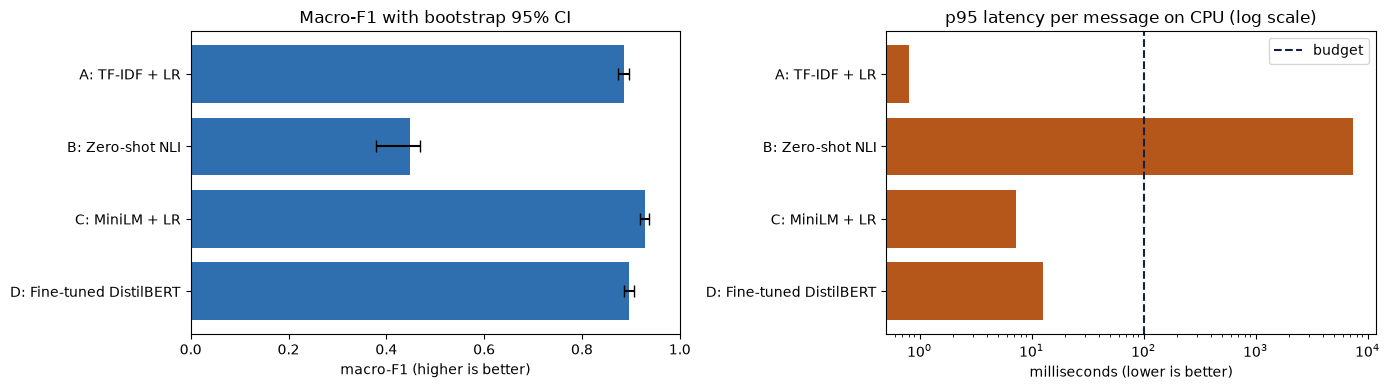

In [ ]:
res_df = pd.DataFrame(RESULTS_ALL.values()).set_index("candidate")
res_df["meets latency"] = np.where(res_df["p95_ms_cpu"] <= CONSTRAINTS["p95_latency_ms_cpu"], "yes", "NO")
display(res_df[["macro_f1", "ci95_low", "ci95_high", "p95_ms_cpu", "meets latency", "size_mb", "n_eval"]])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
y = np.arange(len(res_df))
err = [res_df["macro_f1"] - res_df["ci95_low"], res_df["ci95_high"] - res_df["macro_f1"]]
ax[0].barh(y, res_df["macro_f1"], xerr=err, color="#2F6FB0", capsize=4)
ax[0].set_yticks(y, res_df.index); ax[0].invert_yaxis(); ax[0].set_xlim(0, 1)
ax[0].set_title("Macro-F1 with bootstrap 95% CI"); ax[0].set_xlabel("macro-F1 (higher is better)")
ax[1].barh(y, res_df["p95_ms_cpu"], color="#B5561A"); ax[1].set_xscale("log")
ax[1].axvline(CONSTRAINTS["p95_latency_ms_cpu"], color="#14213D", ls="--", label="budget")
ax[1].set_yticks(y, res_df.index); ax[1].invert_yaxis(); ax[1].legend()
ax[1].set_title("p95 latency per message on CPU (log scale)"); ax[1].set_xlabel("milliseconds (lower is better)")
plt.tight_layout(); plt.show()

In [ ]:
print("Worst five intents by recall (where misroutes concentrate):\n")
for name, r in RESULTS_ALL.items():
    print(f"{r['candidate']:28s}", ", ".join(f"{k} ({v:.2f})" for k, v in r["worst_recalls"].items()))

Worst five intents by recall (where misroutes concentrate):

A: TF-IDF + LR               pending_transfer (0.72), topping_up_by_card (0.72), virtual_card_not_working (0.72), wrong_exchange_rate_for_cash_withdrawal (0.72), card_payment_not_recognised (0.75)
B: Zero-shot NLI             apple_pay_or_google_pay (0.00), atm_support (0.00), card_arrival (0.00), beneficiary_not_allowed (0.00), card_delivery_estimate (0.00)
C: MiniLM + LR               pending_transfer (0.69), balance_not_updated_after_bank_transfer (0.72), declined_transfer (0.72), compromised_card (0.82), direct_debit_payment_not_recognised (0.82)
D: Fine-tuned DistilBERT     virtual_card_not_working (0.40), why_verify_identity (0.60), get_disposable_virtual_card (0.68), balance_not_updated_after_bank_transfer (0.70), declined_transfer (0.72)


**Things to draw out**
- Zero-shot (B) was evaluated on a sample. Note its **n_eval**, and how its latency compares with the budget. A failed hard constraint is a **filter, not a weight**.
- How close does C get to D, at what fraction of the training and serving cost?
- Do the confidence intervals of the top two overlap? If so, the matrix, not the point estimate, has to decide.
- Are the worst intents the same across models? Shared weak spots often mean ambiguous labels, which is a data problem rather than a model problem.

### 💡 KEY IDEAS: Make the choice explicit with a weighted matrix
1. **Apply hard filters** (latency, license, data control). A candidate that fails one is out, however well it scores.
2. **Score the survivors** from *measured* numbers, not opinion.
3. **Stress the weights.** If the winner flips when one weight changes, the decision hinges on that criterion, so argue it out loud.

The weights make value judgments visible and debatable. That visibility, more than the arithmetic, is the point.

In [ ]:
# Judgment calls are labeled as such. Everything else comes from measurements above.
OPS_EFFORT = {"A": 5, "B": 4, "C": 4, "D": 3}          # 1-5, higher = easier to run (judgment)
LICENSE = {"A": "bsd-3-clause",                        # scikit-learn, trained in-house
           "B": REVIEWS[ZS_ID]["license"], "C": REVIEWS[EMB_ID]["license"], "D": REVIEWS[FT_BASE]["license"]}
WEIGHTS = {"quality": 0.40, "latency": 0.15, "cost": 0.20, "data_control": 0.15, "ops": 0.10}

rows = []
for k, r in RESULTS_ALL.items():
    reasons = []
    if r["p95_ms_cpu"] > CONSTRAINTS["p95_latency_ms_cpu"]: reasons.append("latency")
    if LICENSE[k] not in CONSTRAINTS["allowed_licenses"]: reasons.append(f"license ({LICENSE[k]})")
    rows.append({"key": k, "candidate": r["candidate"], "macro_f1": r["macro_f1"], "p95_ms": r["p95_ms_cpu"],
                 "size_mb": r["size_mb"], "license": LICENSE[k], "filtered_by": ", ".join(reasons) or "-"})
rows.append({"key": "E", "candidate": "E: Hosted LLM API (not run)", "macro_f1": np.nan, "p95_ms": np.nan,
             "size_mb": np.nan, "license": "vendor terms",
             "filtered_by": "data control" if not CONSTRAINTS["data_may_leave_environment"] else "-"})
matrix = pd.DataFrame(rows).set_index("key")
survivors = matrix[matrix["filtered_by"] == "-"].copy()
display(matrix)

,candidate,macro_f1,p95_ms,size_mb,license,filtered_by
key,,,,,,
A,A: TF-IDF + LR,0.8864,0.8,13.6,bsd-3-clause,-
B,B: Zero-shot NLI,0.4478,7461.2,1553.9,mit,latency
C,C: MiniLM + LR,0.9293,7.3,86.8,apache-2.0,-
D,D: Fine-tuned DistilBERT,0.8971,12.7,255.6,apache-2.0,-
E,E: Hosted LLM API (not run),NaN,NaN,NaN,vendor terms,data control


In [ ]:
def scale(s, higher_better=True, log=False):
    # Min-max to 1..5 across the survivors. With few candidates this exaggerates gaps; say so in class.
    v = np.log10(s) if log else s
    if v.max() == v.min():
        return pd.Series(5.0, index=s.index)
    z = (v - v.min()) / (v.max() - v.min())
    return 1 + 4 * (z if higher_better else 1 - z)

def score(survivors, weights):
    s = pd.DataFrame(index=survivors.index)
    s["quality"] = scale(survivors["macro_f1"])
    s["latency"] = scale(survivors["p95_ms"], higher_better=False, log=True)
    s["cost"] = scale(survivors["size_mb"], higher_better=False, log=True)   # proxy: serving footprint
    s["data_control"] = 5.0                                                   # all survivors run in-house
    s["ops"] = [OPS_EFFORT[k] for k in s.index]
    w = pd.Series(weights) / sum(weights.values())
    s["weighted_total"] = (s[list(w.index)] * w).sum(axis=1)
    return s.round(2).sort_values("weighted_total", ascending=False)

if len(survivors) == 0:
    print("Every candidate failed a hard constraint. Revisit the constraints or the shortlist.")
else:
    scored = score(survivors, WEIGHTS)
    scored.index = [survivors.loc[k, "candidate"] for k in scored.index]
    WINNER = scored.index[0]
    display(scored)
    print(f"Winner under the stated weights: {WINNER}")

,quality,latency,cost,data_control,ops,weighted_total
C: MiniLM + LR,5.0,1.8,2.47,5.0,4,3.91
A: TF-IDF + LR,1.0,5.0,5.00,5.0,5,3.40
D: Fine-tuned DistilBERT,2.0,1.0,1.00,5.0,3,2.20


Winner under the stated weights: C: MiniLM + LR


In [ ]:
# Sensitivity: double or halve each weight in turn (others rescale). Does the winner change?
if len(survivors) > 1:
    flips = []
    for crit in WEIGHTS:
        for factor in (0.5, 2.0):
            w = dict(WEIGHTS); w[crit] *= factor
            s = score(survivors, w)
            top = survivors.loc[s.index[0], "candidate"]
            flips.append({"change": f"{crit} x{factor}", "winner": top, "flipped": "YES" if top != WINNER else ""})
    display(pd.DataFrame(flips))

,change,winner,flipped
0,quality x0.5,A: TF-IDF + LR,YES
1,quality x2.0,C: MiniLM + LR,
2,latency x0.5,C: MiniLM + LR,
3,latency x2.0,C: MiniLM + LR,
4,cost x0.5,C: MiniLM + LR,
5,cost x2.0,A: TF-IDF + LR,YES
6,data_control x0.5,C: MiniLM + LR,
7,data_control x2.0,C: MiniLM + LR,
8,ops x0.5,C: MiniLM + LR,
9,ops x2.0,C: MiniLM + LR,


🙋 **ASK THE ROOM:** Which single criterion decided this? Would a stakeholder from finance weigh it the same way as one from customer experience?

**Record the decision.** The filters, scores, weights, and sensitivity check go into the model card below, so a future reviewer can see *why* this model shipped.

---
## 3 · Use: deploy, monitor, operate responsibly

From here we package **D, the fine-tuned DistilBERT**. It exercises the full Hub workflow: model card, push, and a pinned revision. If your matrix picked C, the same steps apply with `SentenceTransformer.save()` and `push_to_hub()`.

### 💡 KEY IDEAS: Pick a serving pattern, then roll out gradually
| Pattern | When | Example |
|---|---|---|
| **Batch** | Score on a schedule, write to a table | Nightly churn scores |
| **Online** | Synchronous API per request; latency budget rules | **Ticket routing at submit time** |
| **Streaming** | Score events as they arrive from a queue | Fraud checks on transactions |

**Offline eval → Shadow → Canary → Full rollout.** Version data, code, weights, and config together, so any prediction can be traced and any release rolled back.

### Step 1: Write the model card, including the decision record

In [24]:
from huggingface_hub import ModelCard

d = RESULTS_ALL["D"]
card = f'''---
license: apache-2.0
base_model: {FT_BASE}
datasets: [PolyAI/banking77]
language: [en]
pipeline_tag: text-classification
tags: [intent-classification, course-demo]
---
# banking77 intent router (course demo)

## Intended use
Routes English customer-support messages from a retail bank into one of 77 intents.
Out of scope: other languages, other domains, messages that fit none of the 77 intents
(the model will still pick one: use the confidence threshold and fallback queue).

## Training data
banking77 train split ({len(train_df):,} messages after a 10% validation hold-out), from {DATA_SOURCE}.
Original license: CC-BY-4.0 (PolyAI).

## Evaluation (frozen test split, fingerprint {TEST_FINGERPRINT})
- Macro-F1: {d["macro_f1"]:.3f} (95% bootstrap CI {d["ci95_low"]:.3f}-{d["ci95_high"]:.3f})
- p95 latency, single message on CPU: {d["p95_ms_cpu"]:.0f} ms
- Weakest intents by recall: {", ".join(d["worst_recalls"])}

## Decision record
Candidates: {", ".join(r["candidate"] for r in RESULTS_ALL.values())}; hosted APIs excluded (data may not leave the environment).
Weights: {WEIGHTS}. Winner under these weights: {globals().get("WINNER", "n/a")}.
Shipped: D (fine-tuned {FT_BASE}). If that differs from the winner, record why here: [reason].

## Limitations
Single-domain, English-only, synthetic-feeling phrasing; no out-of-scope class; confidence is not calibrated.

## How to load
`pipeline("text-classification", model=<repo>, revision=<commit sha>, trust_remote_code=False)`
'''
ModelCard(card).save(FT_DIR / "README.md")
print(card)

---
license: apache-2.0
base_model: distilbert-base-uncased
datasets: [PolyAI/banking77]
language: [en]
pipeline_tag: text-classification
tags: [intent-classification, course-demo]
---
# banking77 intent router (course demo)

## Intended use
Routes English customer-support messages from a retail bank into one of 77 intents.
Out of scope: other languages, other domains, messages that fit none of the 77 intents
(the model will still pick one: use the confidence threshold and fallback queue).

## Training data
banking77 train split (8,993 messages after a 10% validation hold-out), from huggingface.co/datasets/mteb/banking77.
Original license: CC-BY-4.0 (PolyAI).

## Evaluation (frozen test split, fingerprint e62ee22558ec)
- Macro-F1: 0.897 (95% bootstrap CI 0.885-0.906)
- p95 latency, single message on CPU: 13 ms
- Weakest intents by recall: virtual_card_not_working, why_verify_identity, get_disposable_virtual_card, balance_not_updated_after_bank_transfer, declined_transfer

## Decision r

### Step 2: Publish privately (optional) and pin the exact commit
Set `PUSH_TO_HUB = True` and run `hf auth login` in the terminal (or set `HF_TOKEN`) first. Then show the new repo page: the model card renders, and **Files and versions** shows `model.safetensors` and the commit history.

In [ ]:
PUSH_TO_HUB = True
HUB_REPO = "jhebelerDS/banking77-router-demo"     # <- change me

SOURCE, REVISION = str(FT_DIR), None
if PUSH_TO_HUB:
    api.create_repo(HUB_REPO, private=True, exist_ok=True)
    commit = api.upload_folder(folder_path=str(FT_DIR), repo_id=HUB_REPO,
                               commit_message=f"banking77 router, test fingerprint {TEST_FINGERPRINT}")
    SOURCE, REVISION = HUB_REPO, commit.oid
    print(f"Pushed: https://huggingface.co/{HUB_REPO}  commit {REVISION}")
print("Will load from:", SOURCE, "| revision:", REVISION)

Will load from: artifacts/distilbert-banking77 | revision: None


### Step 3: Load it safely
### 💡 KEY IDEAS: Three settings, three supply-chain risks
| Setting | Risk it closes |
|---|---|
| `revision="<commit sha>"` | The repo can change under you; a commit can't. |
| `trust_remote_code=False` | Doesn't run Python files shipped inside a model repo |
| `use_safetensors=True` | Pickle weights can **execute code when loaded** |

How real is the pickle risk? Here's a harmless demonstration:

In [27]:
import pickletools

class Payload:
    def __reduce__(self):              # pickle calls this to learn how to "rebuild" the object...
        return (print, ("!!! This code ran just because you loaded the file !!!",))

blob = pickle.dumps(Payload())
pickle.loads(blob)                     # ...so loading runs it. Here it's print(); it could be anything.

print("\nInspecting the same bytes WITHOUT executing them (what the Hub's pickle scan does):")
for op, arg, _ in pickletools.genops(blob):
    if op.name in ("GLOBAL", "STACK_GLOBAL", "SHORT_BINUNICODE", "REDUCE"):
        print(f"  {op.name:18s} {arg if arg is not None else ''}")

!!! This code ran just because you loaded the file !!!

Inspecting the same bytes WITHOUT executing them (what the Hub's pickle scan does):
  SHORT_BINUNICODE   builtins
  SHORT_BINUNICODE   print
  STACK_GLOBAL       
  SHORT_BINUNICODE   !!! This code ran just because you loaded the file !!!
  REDUCE             


In [28]:
router_pipe = pipeline("text-classification", model=SOURCE, revision=REVISION,
                       trust_remote_code=False, model_kwargs={"use_safetensors": True},
                       device=DEVICE)
router_pipe("my card still hasn't arrived and it's been two weeks")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'card_arrival', 'score': 0.8518085479736328}]

### Step 4: Choose a confidence threshold and a fallback
A closed set of 77 labels always picks *something*. We pick a confidence threshold on the **validation** split (never the test split). Below the threshold, a message goes to a human queue. The trade-off is coverage (how much the model handles) versus accuracy on what it handles.

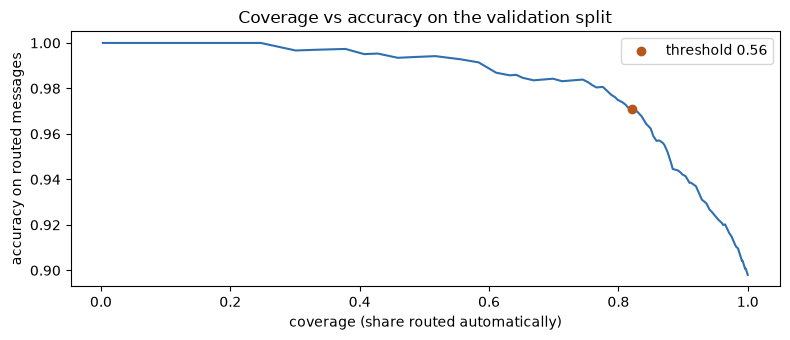

Threshold 0.56: model routes 82% automatically at 97.1% accuracy; the rest go to a human queue.


In [29]:
val_out = router_pipe(val_df["text"].tolist(), batch_size=128, truncation=True)
val_conf = np.array([o["score"] for o in val_out])
val_ok = np.array([o["label"] == t for o, t in zip(val_out, val_df["intent"])])

TARGET_ACC = 0.97
grid = np.linspace(0, 0.99, 100)
curve = pd.DataFrame({"threshold": grid,
                      "coverage": [(val_conf >= t).mean() for t in grid],
                      "accuracy_on_covered": [val_ok[val_conf >= t].mean() if (val_conf >= t).any() else np.nan for t in grid]})
ok = curve[curve["accuracy_on_covered"] >= TARGET_ACC]
if len(ok):
    THRESHOLD = float(ok["threshold"].iloc[0])     # lowest threshold that meets the target = most coverage
else:
    # The model never reaches the target. Keep 80% coverage and say so: this is a finding, not a bug.
    THRESHOLD = float(np.quantile(val_conf, 0.2))
    print(f"No threshold reaches {TARGET_ACC:.0%} accuracy; using the 80%-coverage threshold instead.")
cov = (val_conf >= THRESHOLD).mean()
acc_cov = val_ok[val_conf >= THRESHOLD].mean() if cov > 0 else float("nan")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(curve["coverage"], curve["accuracy_on_covered"], color="#2F6FB0")
ax.scatter([cov], [acc_cov], color="#B5561A", zorder=3, label=f"threshold {THRESHOLD:.2f}")
ax.set_xlabel("coverage (share routed automatically)"); ax.set_ylabel("accuracy on routed messages")
ax.set_title("Coverage vs accuracy on the validation split"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Threshold {THRESHOLD:.2f}: model routes {cov:.0%} automatically at {acc_cov:.1%} accuracy; "
      "the rest go to a human queue.")

In [30]:
def route(message):
    out = router_pipe(message, truncation=True)[0]
    if out["score"] < THRESHOLD:
        return {"queue": "human_review", "model_guess": out["label"], "confidence": round(out["score"], 3)}
    return {"queue": out["label"], "confidence": round(out["score"], 3)}

route("I was charged twice for the same coffee")

{'queue': 'transaction_charged_twice', 'confidence': 0.896}

### Step 5: Try to break it
🙋 **ASK THE ROOM:** Give me a message this model was never meant to see.

In [31]:
out_of_scope = [
    "What's the weather like in Baltimore tomorrow?",
    "Can you recommend a good mortgage rate?",
    "I want to talk to a human",
    "asdfgh jkl",
    "My dog ate my card lol",
    "Is the branch on Main Street open on Sunday?",
    "¿Dónde está mi tarjeta?",
    "Your app is great, thanks!",
]
pd.DataFrame([{"message": m, **route(m)} for m in out_of_scope])

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,message,queue,model_guess,confidence
0,What's the weather like in Baltimore tomorrow?,human_review,card_delivery_estimate,0.450
1,Can you recommend a good mortgage rate?,human_review,exchange_rate,0.235
2,I want to talk to a human,human_review,edit_personal_details,0.090
3,asdfgh jkl,human_review,beneficiary_not_allowed,0.111
4,My dog ate my card lol,human_review,reverted_card_payment?,0.142
5,Is the branch on Main Street open on Sunday?,human_review,card_delivery_estimate,0.216
6,¿Dónde está mi tarjeta?,human_review,request_refund,0.059
7,"Your app is great, thanks!",human_review,card_linking,0.125


In [32]:
LAUNCH_UI = False   # set True to open a small web UI the class can try (port 7860 on your server)
if LAUNCH_UI:
    import gradio as gr
    gr.Interface(fn=route, inputs=gr.Textbox(label="Customer message"), outputs=gr.JSON(label="Routing"),
                 title="banking77 router (course demo)",
                 examples=["I lost my card", "Why was I charged a fee?", "What's the weather?"]
                 ).launch(server_name="0.0.0.0", server_port=7860)

### Step 6: Monitor drift and decide the response in advance
| What changes | Signal to watch | Typical response |
|---|---|---|
| Inputs (data drift) | Distribution of predicted intents, confidence | Check the pipeline, then retrain |
| Input → label link (concept drift) | Live macro-F1 on delayed labels | Relabel and retrain |
| Quality without labels | Share below threshold, user feedback, audits | Human review sample |
| The system | p95 latency, error rate, cost | Scale, optimize, fall back |

**Write retraining triggers and the fallback path before launch, not after the incident.**

Let's simulate "next week": a new card launch triples card-related traffic, the app's new keyboard introduces typos, and off-topic messages rise.

,baseline (test split),next week (simulated)
JS distance of predicted-intent mix,0.000,0.175
mean confidence,0.724,0.610
share sent to human review,0.194,0.369


Macro-F1 on in-scope messages once labels arrive: 0.799 (test: 0.897)


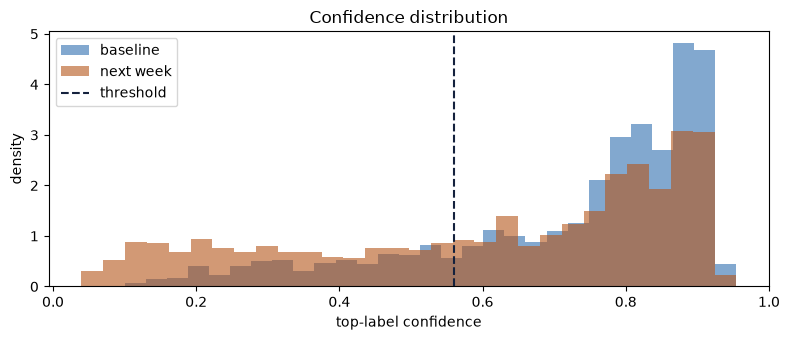

In [33]:
from scipy.spatial.distance import jensenshannon

rng = random.Random(SEED)
def add_typos(s, rate=0.08):
    chars = list(s)
    for i in range(len(chars)):
        if chars[i].isalpha() and rng.random() < rate:
            chars[i] = rng.choice("abcdefghijklmnopqrstuvwxyz")
    return "".join(chars)

boost = test_df[test_df["intent"].str.contains("card")]
week2 = pd.concat([test_df, boost, boost], ignore_index=True)
week2["text"] = [add_typos(t) if rng.random() < 0.3 else t for t in week2["text"]]
week2 = pd.concat([week2, pd.DataFrame({"text": out_of_scope * 20, "intent": "out_of_scope"})], ignore_index=True)

def snapshot(df):
    out = router_pipe(df["text"].tolist(), batch_size=128, truncation=True)
    labels = pd.Series([o["label"] for o in out]); conf = np.array([o["score"] for o in out])
    return labels, conf

base_labels, base_conf = snapshot(test_df)
new_labels, new_conf = snapshot(week2)

dist = lambda s: s.value_counts(normalize=True).reindex(LABELS, fill_value=0).values
monitor = pd.DataFrame({
    "baseline (test split)": [0.0, base_conf.mean(), (base_conf < THRESHOLD).mean()],
    "next week (simulated)": [jensenshannon(dist(base_labels), dist(new_labels)), new_conf.mean(), (new_conf < THRESHOLD).mean()],
}, index=["JS distance of predicted-intent mix", "mean confidence", "share sent to human review"]).round(3)
display(monitor)

in_scope = week2["intent"] != "out_of_scope"
live_f1 = f1_score(week2.loc[in_scope, "intent"], new_labels[in_scope.values], average="macro", labels=LABELS, zero_division=0)
print(f"Macro-F1 on in-scope messages once labels arrive: {live_f1:.3f} (test: {RESULTS_ALL['D']['macro_f1']:.3f})")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(base_conf, bins=30, alpha=0.6, label="baseline", color="#2F6FB0", density=True)
ax.hist(new_conf, bins=30, alpha=0.6, label="next week", color="#B5561A", density=True)
ax.axvline(THRESHOLD, color="#14213D", ls="--", label="threshold")
ax.set_xlabel("top-label confidence"); ax.set_ylabel("density"); ax.set_title("Confidence distribution")
ax.legend(); plt.tight_layout(); plt.show()

In [34]:
TRIGGERS = {   # decided before launch
    "JS distance of predicted-intent mix": 0.10,
    "share sent to human review": 0.25,
}
for metric, limit in TRIGGERS.items():
    value = monitor.loc[metric, "next week (simulated)"]
    print(f"{'ALERT' if value > limit else 'ok   '}  {metric}: {value:.3f} (limit {limit})")

ALERT  JS distance of predicted-intent mix: 0.175 (limit 0.1)
ALERT  share sent to human review: 0.369 (limit 0.25)


### 💡 KEY IDEAS: Operate it responsibly and securely
| Responsible use | Security |
|---|---|
| Report results **by slice**, not just overall (our worst-intent recalls) | Verify weight sources; prefer safetensors; pin commits |
| Write a model card for *your* system (done above) | Keep `trust_remote_code=False` unless you've read the code |
| Keep a human in the loop where errors harm people (our threshold) | In LLM apps, treat **prompt injection** as a real threat |
| Tell users when a model is making the call | Access control and rate limits on endpoints; models can leak training data |

---
## 4 · Debrief

🙋 **Three questions for the room**
1. **The evidence:** What did the model cards, download counts, and leaderboard fail to tell us?
2. **The deciding factor:** Which constraint or weight actually made the choice?
3. **The rerun:** What would make us redo this decision in six months? (Drift past a trigger, new intents from a product launch, a cheaper or better model, a change in data-control rules that brings hosted APIs back in.)

### Takeaways
1. Frame the decision and price the errors **before** naming a model.
2. **Constraints filter; your own eval set ranks; benchmarks only shortlist.**
3. Start simple and climb the adaptation ladder only when the eval demands it.
4. Shipping starts the work: monitor, retrain, and keep a fallback.

### Team activity (15 minutes)
Take one prediction task from your project. Write the hard constraints as tests, shortlist three candidates from the Hub (one per ladder rung), review their cards with `review_model()`, and fill in the weighted matrix. Be ready to defend your weights, and to tell us whether the winner flips.

---
## Appendix: Troubleshooting

| Symptom | Fix |
|---|---|
| `CUDA error: no kernel image is available` | Pascal (GTX 10xx) needs `pip install torch==2.14.0 --index-url https://download.pytorch.org/whl/cu126` |
| `Dataset scripts are no longer supported` | You loaded `PolyAI/banking77`; use `mteb/banking77` (this notebook does) |
| Hub unreachable in class | Pre-run with `HF_HOME` set, then `HF_HUB_OFFLINE=1`; the dataset falls back to GitHub |
| Fine-tuning OOM | Lower `per_device_train_batch_size` to 16 |
| Want a fast dry run | `DEMO_QUICK=1 jupyter lab`: tiny subsets, 1 epoch |
| Start the slow steps fresh | Delete `artifacts/` or set `RERUN_ZERO_SHOT` / `RERUN_FINETUNE` |